# S2: channel spacing implied by the hammer taps

For each pair of consecutive reviewed taps, the length of walked route between
their assigned points divided by the number of channels between them. It would
equal the nominal 3.19 m channel spacing if the cable lay exactly along the
walked route and every pick and GPS fix were exact.

Reads `outputs/tap_localization/` (run the tap-localization notebook first).

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from das_tools.utils import proj_path

TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LEGEND_FONTSIZE = 12

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

RESULTS_DIR = proj_path.output_dir("tap_localization")

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUT_PDF = FIGURE_DIR / "walked_route_registration.pdf"

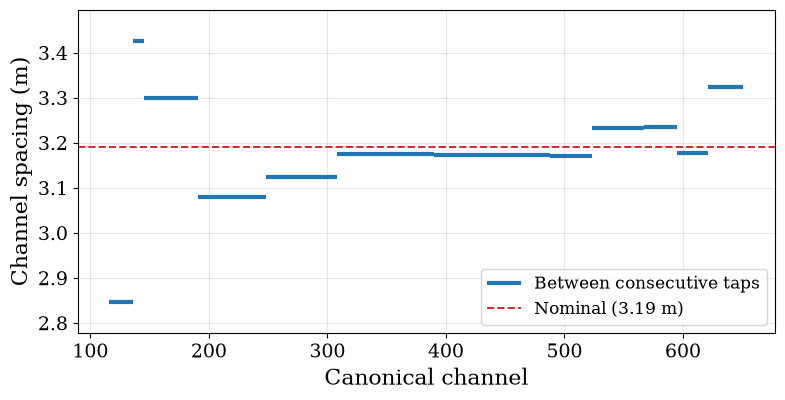

Saved: figures/walked_route_registration.pdf


In [2]:
segments = pd.read_csv(RESULTS_DIR / "anchor_segments.csv")
nominal = json.loads((RESULTS_DIR / "summary.json").read_text())["nominal_spacing_m"]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hlines(segments["implied_spacing_m"], segments["channel_start"], segments["channel_end"],
          color="tab:blue", lw=3, label="Between consecutive taps")
ax.axhline(nominal, color="tab:red", ls="--", lw=1.4, label=f"Nominal ({nominal:.2f} m)")
ax.set_xlabel("Canonical channel")
ax.set_ylabel("Channel spacing (m)")
ax.grid(alpha=0.3)
ax.margins(y=0.12)
ax.legend(loc="lower right")

fig.savefig(OUT_PDF, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PDF}")